In [64]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import random
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re

In [65]:
import re
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [66]:
!pip install catboost

In [67]:
!pip install lightgbm

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from catboost import CatBoostRegressor


In [69]:
df_og = pd.read_csv('coursera_data.csv')

In [70]:
df = df_og.iloc[0:6000]

In [71]:
df.head()

,title,partners,platform,url,rating,learner_count,certificate_type,difficulty_workload,cost,tags,snippet,description
0,Getting started with the Vertex AI Gemini 1.5 ...,['Google Cloud'],Coursera,https://www.coursera.org/learn/googlecloud-get...,NaN,NaN,Shareable certificate,1 hour 30 minutes,Free + paid certificate,"['information technology', 'cloud computing', ...",This is a self-paced lab that takes place in t...,This is a self-paced lab that takes place in t...
1,SPSS: Apply & Interpret Logistic Regression Mo...,['EDUCBA'],Coursera,https://www.coursera.org/learn/spss-apply-inte...,5.00000,NaN,Shareable certificate,NaN,Free + paid certificate,"['data science', 'data analysis']",This course provides a practical and applied i...,This course provides a practical and applied i...
2,Securing Compute Engine Applications and Resou...,['Google Cloud'],Coursera,https://www.coursera.org/learn/googlecloud-sec...,NaN,NaN,Shareable certificate,1 hour 30 minutes,Free + paid certificate,"['information technology', 'cloud computing', ...",This is a self-paced lab that takes place in t...,This is a self-paced lab that takes place in t...
3,Overcoming Challenges in Self and Society,['University of Colorado System'],Coursera,https://www.coursera.org/learn/overcoming-chal...,NaN,NaN,Shareable certificate,"4 weeks of study, 2-4 hours a week",Free + paid certificate,"['personal development', 'personal development...",This course is an personal development and aca...,This course is an personal development and aca...
4,Gamification,['University of Pennsylvania'],Coursera,https://www.coursera.org/learn/gamification,4.77074,"162,319",Shareable certificate,4-8 hours/week,Free + paid certificate,"['computer science', 'design and product', 'bu...",Gamification is the application of game elemen...,Gamification is the application of game elemen...


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   title                6000 non-null   object 
 1   partners             6000 non-null   object 
 2   platform             6000 non-null   object 
 3   url                  6000 non-null   object 
 4   rating               2435 non-null   float64
 5   learner_count        3137 non-null   object 
 6   certificate_type     6000 non-null   object 
 7   difficulty_workload  3648 non-null   object 
 8   cost                 6000 non-null   object 
 9   tags                 6000 non-null   object 
 10  snippet              6000 non-null   object 
 11  description          6000 non-null   object 
dtypes: float64(1), object(11)
memory usage: 562.6+ KB


In [73]:
df.describe()

,rating
count,2435.000000
mean,4.622274
std,0.252999
min,3.000000
25%,4.541104
50%,4.686375
75%,4.777891
max,5.000000


In [74]:
df.describe(include="O")

,title,partners,platform,url,learner_count,certificate_type,difficulty_workload,cost,tags,snippet,description
count,6000,6000,6000,6000,3137,6000,3648,6000,6000,6000,6000
unique,5934,359,1,5947,2921,7,1399,1,671,5126,5925
top,PM4R Agile: 5 steps for hybrid management of p...,['Coursera'],Coursera,https://www.coursera.org/learn/foundations-of-...,"1,545",Shareable certificate,2 hours,Free + paid certificate,"['computer science', 'software development', '...",Updated in May 2025.,This comprehensive course equips learners with...
freq,2,748,6000,2,4,5838,239,6000,153,254,2


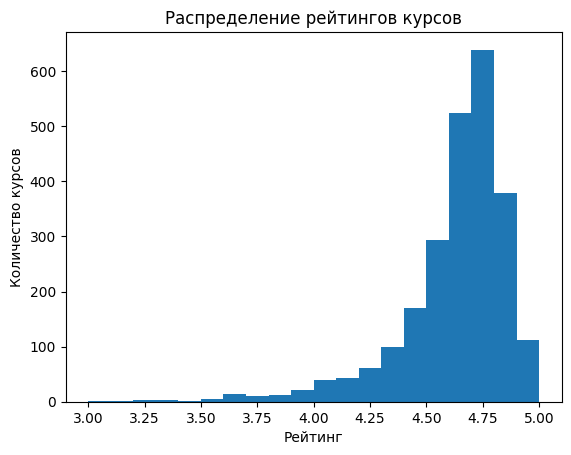

In [75]:
plt.figure()
df["rating"].dropna().plot(kind="hist", bins=20)
plt.title("Распределение рейтингов курсов")
plt.xlabel("Рейтинг")
plt.ylabel("Количество курсов")
plt.show()

In [76]:
top_partners = (
    df["partners"]
    .dropna()
    .explode()
    .value_counts()
    .head(10)
)

top_partners


partners
['Coursera']                                   748
['Packt']                                      575
['Google Cloud']                               348
['EDUCBA']                                     240
['University of Colorado Boulder']             160
['Johns Hopkins University']                   137
['Pearson']                                    121
['University of Michigan']                     109
['Microsoft']                                  105
['University of Illinois Urbana-Champaign']     99
Name: count, dtype: int64

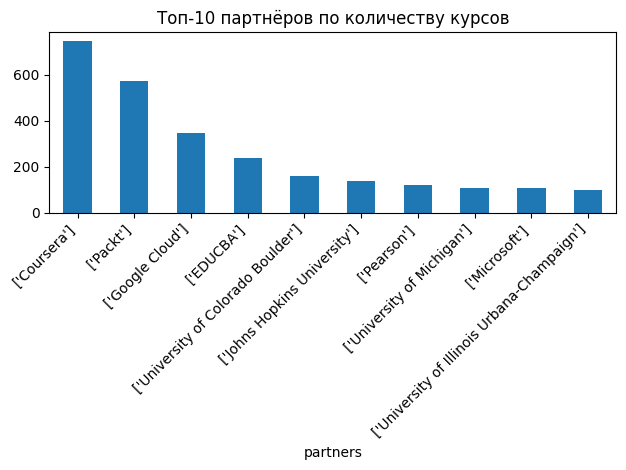

In [77]:
ax = top_partners.plot(kind="bar", title="Топ-10 партнёров по количеству курсов")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

In [78]:
pink_colors = [
    "#FFD1DC", "#FFB6C1", "#FF9BB5", "#FF82AB",
    "#FF00FF", "#EE1289", "#D02090", "#DA70D6",
    "#9370DB", "#8A2BE2", "#9400D3", "#9932CC", "#8B008B"
]

In [79]:
def plot_wordcloud(words, title):
    wordcloud_text = ' '.join(words)
    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        color_func=lambda *args, **kwargs: random.choice(pink_colors)
    ).generate(wordcloud_text)

    plt.figure(figsize=(15, 7))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=20)
    plt.show()

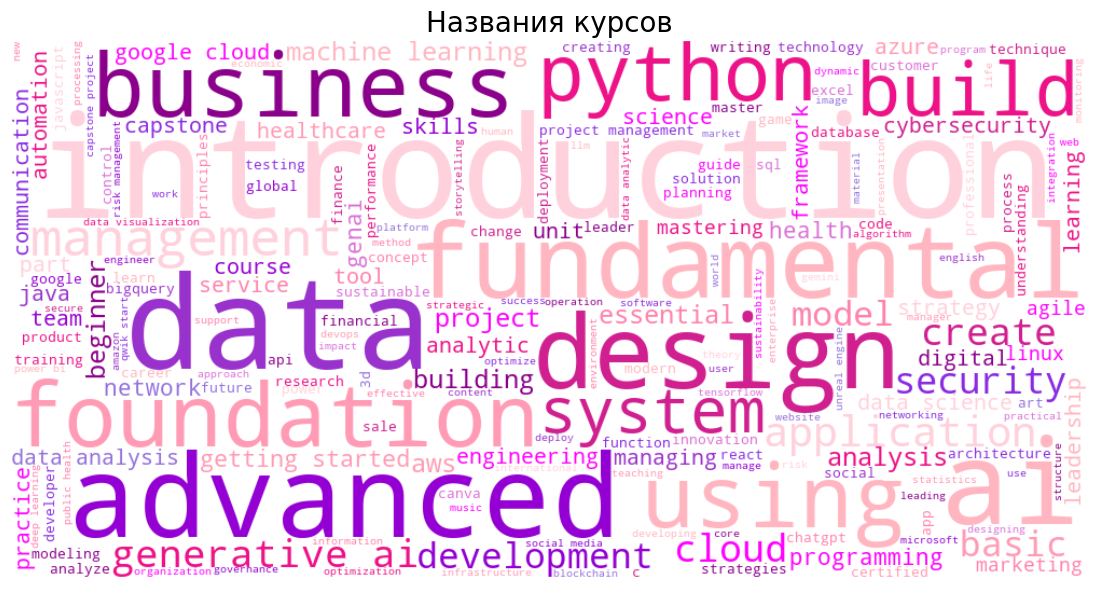

In [80]:
titles_words = (
    df["title"]
    .dropna()
    .astype(str)
    .str.lower()
    .str.split()
    .explode()
)

plot_wordcloud(titles_words.tolist(), "Названия курсов")


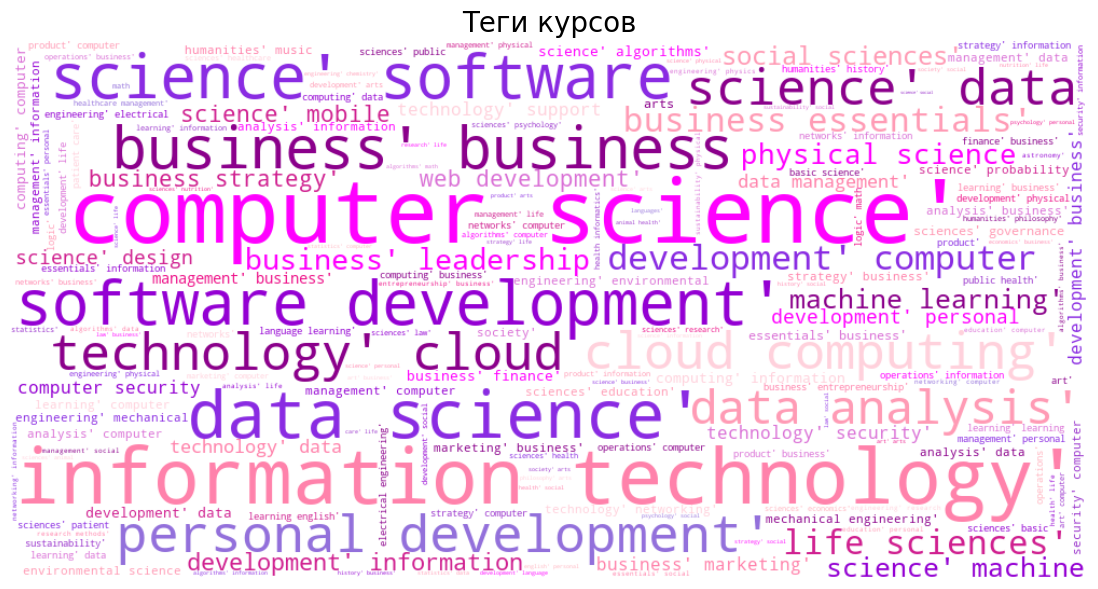

In [81]:
tags_words = (
    df["tags"]
    .dropna()
    .explode()
    .astype(str)
)

plot_wordcloud(tags_words.tolist(), "Теги курсов")


#### пропуски

In [82]:
missing_df = (
    df.isna()
      .sum()
      .to_frame(name="missing_count")
      .assign(missing_ratio=lambda x: x["missing_count"] / len(df))
      .sort_values("missing_count", ascending=False)
)

missing_df


,missing_count,missing_ratio
rating,3565,0.594167
learner_count,2863,0.477167
difficulty_workload,2352,0.392000
title,0,0.000000
partners,0,0.000000
platform,0,0.000000
url,0,0.000000
certificate_type,0,0.000000
cost,0,0.000000
tags,0,0.000000


количество студентов

In [83]:
df = df.dropna(subset=["learner_count"])

рейтинг

In [84]:
def clean_learners(x):
    if pd.isna(x):
        return 0
    x = str(x).lower().replace(',', '') # Убираем запятые, приводим к нижнему регистру
    if 'k' in x:
        return float(x.replace('k', '')) * 1000
    if 'm' in x:
        return float(x.replace('m', '')) * 1000000
    try:
        return float(x)
    except:
        return 0

In [85]:
df['learner_count_num'] = df['learner_count'].apply(clean_learners)

In [86]:
df = df.dropna(subset=['rating'])

In [87]:
df["rating"] = df["rating"].fillna(df["rating"].median())

In [88]:
missing_df = (
    df.isna()
      .sum()
      .to_frame(name="missing_count")
      .assign(missing_ratio=lambda x: x["missing_count"] / len(df))
      .sort_values("missing_count", ascending=False)
)

missing_df

,missing_count,missing_ratio
difficulty_workload,767,0.342411
title,0,0.000000
partners,0,0.000000
platform,0,0.000000
url,0,0.000000
rating,0,0.000000
learner_count,0,0.000000
certificate_type,0,0.000000
cost,0,0.000000
tags,0,0.000000


In [89]:
def extract_difficulty(x):
    x = str(x).lower()
    if 'beginner' in x: return 'Beginner'
    if 'intermediate' in x: return 'Intermediate'
    if 'advanced' in x: return 'Advanced'
    return 'None' # Если не указано или смешанный уровень

In [90]:
df['difficulty_level'] = df['difficulty_workload'].apply(extract_difficulty)

In [91]:
def parse_workload(text):
    if pd.isna(text):
        return np.nan

    text = text.lower()

    # Диапазон часов
    range_match = re.search(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)\s*hour', text)
    if range_match:
        low = float(range_match.group(1))
        high = float(range_match.group(2))
        return (low + high) / 2

    # Часы + минуты
    hm_match = re.search(r'(\d+)\s*hour.*?(\d+)\s*minute', text)
    if hm_match:
        hours = int(hm_match.group(1))
        minutes = int(hm_match.group(2))
        return hours + minutes / 60

    # Одиночное число часов
    hours_match = re.search(r'(\d+\.?\d*)\s*hour', text)
    if hours_match:
        return float(hours_match.group(1))

    # Недели + часы в неделю
    weeks_match = re.search(r'(\d+)\s*week', text)
    hours_per_week_match = re.search(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)\s*hour', text)

    if weeks_match and hours_per_week_match:
        weeks = int(weeks_match.group(1))
        low = float(hours_per_week_match.group(1))
        high = float(hours_per_week_match.group(2))
        return weeks * (low + high) / 2

    return np.nan


In [92]:
df["workload_hours"] = df["difficulty_workload"].apply(parse_workload)

In [93]:
df.head()

,title,partners,platform,url,rating,learner_count,certificate_type,difficulty_workload,cost,tags,snippet,description,learner_count_num,difficulty_level,workload_hours
4,Gamification,['University of Pennsylvania'],Coursera,https://www.coursera.org/learn/gamification,4.770740,"162,319",Shareable certificate,4-8 hours/week,Free + paid certificate,"['computer science', 'design and product', 'bu...",Gamification is the application of game elemen...,Gamification is the application of game elemen...,162319.0,None,6.0
6,Dealing With Missing Data,"['University of Maryland, College Park']",Coursera,https://www.coursera.org/learn/missing-data,3.797101,"12,375",Shareable certificate,"4 weeks of study, 1-2 hours/week",Free + paid certificate,"['data science', 'data analysis', 'social scie...",This course will cover the steps used in weigh...,This course will cover the steps used in weigh...,12375.0,None,1.5
7,Unordered Data Structures,['University of Illinois Urbana-Champaign'],Coursera,https://www.coursera.org/learn/cs-fundamentals-3,4.726619,"19,881",Shareable certificate,NaN,Free + paid certificate,"['computer science', 'software development']",The Unordered Data Structures course covers th...,The Unordered Data Structures course covers th...,19881.0,None,NaN
10,FinTech Disruptive Innovation: Implications fo...,['The Hong Kong University of Science and Tech...,Coursera,https://www.coursera.org/learn/fintech-disruption,4.784314,"7,455",Shareable certificate,"Around 4 hours of videos in total, plus a fina...",Free + paid certificate,"['business', 'finance', 'business', 'business ...",This course “FinTech Disruptive Innovation: Im...,This course “FinTech Disruptive Innovation: Im...,7455.0,None,4.0
13,Get Started with iOS App Development,['SkillUp'],Coursera,https://www.coursera.org/learn/get-started-wit...,4.500000,"2,443",Shareable certificate,"3 weeks of study, 1–2 hours per week",Free + paid certificate,"['computer science', 'mobile and web developme...",In a world increasingly dominated by mobile te...,In a world increasingly dominated by mobile te...,2443.0,None,2.0


In [94]:
df["workload_hours"] = df["workload_hours"].fillna(
    df["workload_hours"].median()
)

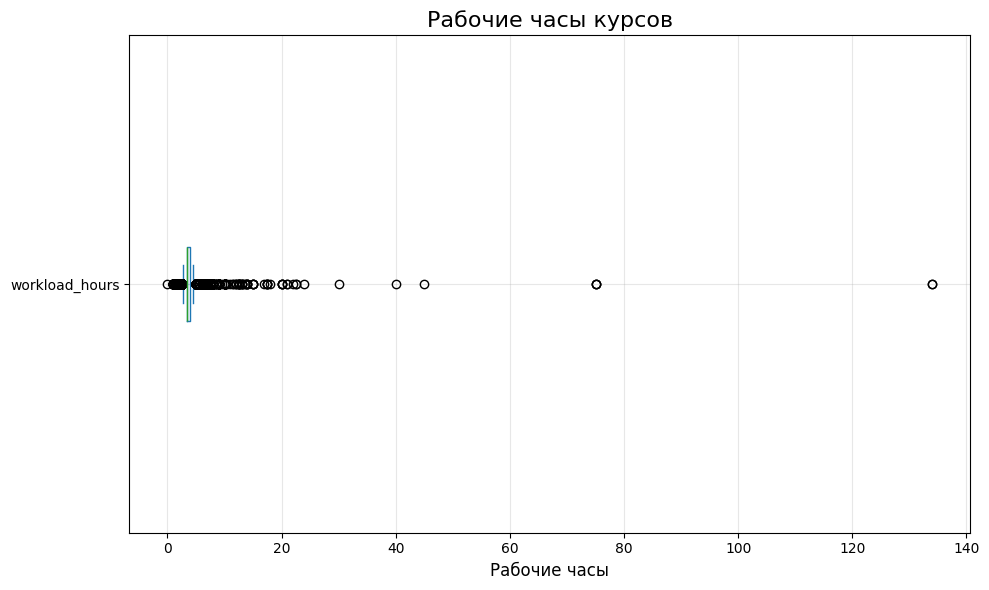

In [95]:
plt.figure(figsize=(10, 6))
df["workload_hours"].plot(kind='box', vert=False)
plt.title("Рабочие часы курсов", fontsize=16)
plt.xlabel("Рабочие часы", fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [96]:
(df['workload_hours'] > 10).sum()

np.int64(51)

In [97]:
(df['workload_hours'] == 0).sum()

np.int64(1)

In [98]:
df = df[(df['workload_hours'] <= 10) & (df['workload_hours'] != 0)]

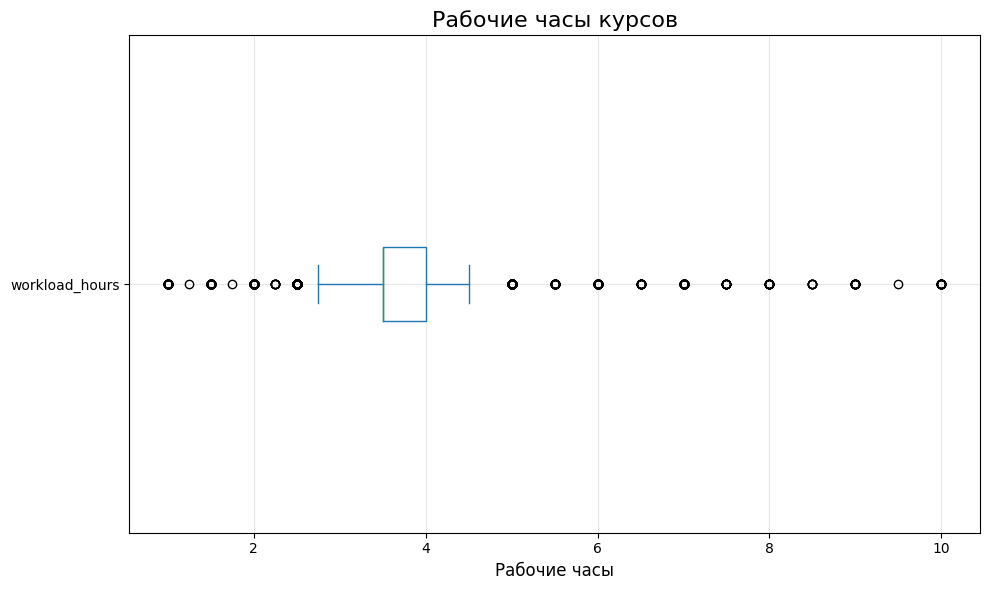

In [99]:
plt.figure(figsize=(10, 6))
df["workload_hours"].plot(kind='box', vert=False)
plt.title("Рабочие часы курсов", fontsize=16)
plt.xlabel("Рабочие часы", fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [100]:
missing_df = (
    df.isna()
      .sum()
      .to_frame(name="missing_count")
      .assign(missing_ratio=lambda x: x["missing_count"] / len(df))
      .sort_values("missing_count", ascending=False)
)

missing_df

,missing_count,missing_ratio
difficulty_workload,767,0.350548
title,0,0.000000
partners,0,0.000000
platform,0,0.000000
url,0,0.000000
rating,0,0.000000
learner_count,0,0.000000
certificate_type,0,0.000000
cost,0,0.000000
tags,0,0.000000


#### дубликаты

In [101]:
pd.Series({
    "total": len(df),
    "duplicate": df.duplicated().sum()
})


total        2188
duplicate      11
dtype: int64

In [102]:
df = df.drop_duplicates()

In [103]:
df.duplicated().sum()

np.int64(0)

### текстовые признаки

In [104]:
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /Users/maryc/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/maryc/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [105]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [106]:
def preprocess_text(text):
    if pd.isna(text):
        return ""

    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))

    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]

    return " ".join(tokens)

In [107]:
df["title_clean"] = df["title"].apply(preprocess_text)
df["description_clean"] = df["description"].apply(preprocess_text)

In [108]:
df["certificate_type"] = df["certificate_type"].str.lower()

In [109]:
def safe_literal_eval(x):
    try:
        return ast.literal_eval(x) if isinstance(x, str) and x.startswith('[') else x
    except:
        return x

In [110]:
df["tags"] = df["tags"].apply(safe_literal_eval)
df["partners"] = df["partners"].apply(safe_literal_eval)

In [111]:
df["partners_text"] = df["partners"].apply(lambda x: " ".join([p.lower() for p in x]) if isinstance(x, list) else "")

In [112]:
df["tags_text"] = df["tags"].apply(
    lambda x: " ".join([t.lower() for t in x]) if isinstance(x, list) else ""
)

In [113]:
df.head()

,title,partners,platform,url,rating,learner_count,certificate_type,difficulty_workload,cost,tags,snippet,description,learner_count_num,difficulty_level,workload_hours,title_clean,description_clean,partners_text,tags_text
4,Gamification,[University of Pennsylvania],Coursera,https://www.coursera.org/learn/gamification,4.770740,"162,319",shareable certificate,4-8 hours/week,Free + paid certificate,"[computer science, design and product, busines...",Gamification is the application of game elemen...,Gamification is the application of game elemen...,162319.0,None,6.0,gamification,gamification application game element digital ...,university of pennsylvania,computer science design and product business m...
6,Dealing With Missing Data,"[University of Maryland, College Park]",Coursera,https://www.coursera.org/learn/missing-data,3.797101,"12,375",shareable certificate,"4 weeks of study, 1-2 hours/week",Free + paid certificate,"[data science, data analysis, social sciences,...",This course will cover the steps used in weigh...,This course will cover the steps used in weigh...,12375.0,None,1.5,dealing missing data,course cover step used weighting sample survey...,"university of maryland, college park",data science data analysis social sciences gov...
7,Unordered Data Structures,[University of Illinois Urbana-Champaign],Coursera,https://www.coursera.org/learn/cs-fundamentals-3,4.726619,"19,881",shareable certificate,NaN,Free + paid certificate,"[computer science, software development]",The Unordered Data Structures course covers th...,The Unordered Data Structures course covers th...,19881.0,None,3.5,unordered data structure,unordered data structure course cover data str...,university of illinois urbana-champaign,computer science software development
10,FinTech Disruptive Innovation: Implications fo...,[The Hong Kong University of Science and Techn...,Coursera,https://www.coursera.org/learn/fintech-disruption,4.784314,"7,455",shareable certificate,"Around 4 hours of videos in total, plus a fina...",Free + paid certificate,"[business, finance, business, business strategy]",This course “FinTech Disruptive Innovation: Im...,This course “FinTech Disruptive Innovation: Im...,7455.0,None,4.0,fintech disruptive innovation implication society,course “fintech disruptive innovation implicat...,the hong kong university of science and techno...,business finance business business strategy
13,Get Started with iOS App Development,[SkillUp],Coursera,https://www.coursera.org/learn/get-started-wit...,4.500000,"2,443",shareable certificate,"3 weeks of study, 1–2 hours per week",Free + paid certificate,"[computer science, mobile and web development,...",In a world increasingly dominated by mobile te...,In a world increasingly dominated by mobile te...,2443.0,None,2.0,get started io app development,world increasingly dominated mobile technology...,skillup,computer science mobile and web development co...


## кодирование

In [114]:
df_ml = df[
    [
        "learner_count",
        "rating",
        "workload_hours",
        "certificate_type",
        "title_clean",
        "description_clean",
        "partners_text",
        "tags_text"
    ]
].copy()

In [115]:
def clean_learner_count(x):
    if pd.isna(x): return 0
    x = str(x).replace(',', '').strip().lower()
    
    if 'k' in x: return float(x.replace('k', '')) * 1000
    if 'm' in x: return float(x.replace('m', '')) * 1000000
    
    try:
        return float(x)
    except ValueError:
        return 0

df_ml["learner_count_num"] = df_ml["learner_count"].apply(clean_learner_count)

In [116]:
df_ml["learner_count_log"] = np.log1p(df_ml["learner_count_num"])

Целевая переменная лог-преобразование

In [117]:
numeric_features = ["rating", "workload_hours"] 
categorical_features = ["certificate_type"]

In [118]:
text_features = [
    "title_clean",
    "description_clean",
    "partners_text",
    "tags_text"
]

In [119]:
X = df_ml.drop(columns=["learner_count", "learner_count_num", "learner_count_log"])
y = df_ml["learner_count_log"]

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [121]:
numeric_features = ["rating", "workload_hours"]
categorical_features = ['certificate_type', 'difficulty_level'] # Наши категории
text_features_title = 'title'
text_features_desc = 'description'

In [122]:
preprocessor = ColumnTransformer(
    transformers=[
        # числовые
        ("num", StandardScaler(), numeric_features),

        # категориальные
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),

        # тексты
        ("title", TfidfVectorizer(max_features=300), "title_clean"),
        ("desc", TfidfVectorizer(max_features=1000), "description_clean"),
        ("partners", TfidfVectorizer(max_features=100), "partners_text"),
        ("tags", TfidfVectorizer(max_features=300), "tags_text"),
    ],
    remainder='drop' 
)

### Ridge Regression

In [123]:
model = Ridge(alpha=1.0)

In [124]:
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ]
)

In [125]:
pipeline.fit(X_train, y_train)

ValueError: A given column is not a column of the dataframe

In [ ]:
y_pred = pipeline.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred) 
r2 = r2_score(y_test, y_pred)

mae, rmse, r2

(0.9762618386853033, 1.226252663362695, 0.20343251801536033)

In [ ]:
y_test_real = np.expm1(y_test)
y_pred_real = np.expm1(y_pred)

mean_absolute_error(y_test_real, y_pred_real)

30521.686612399943

### RandomForestRegressor

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", rf_model)
    ]
)

In [ ]:
rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_rf = rf_pipeline.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = root_mean_squared_error(y_test, y_pred_rf)
r2 = r2_score(y_test, y_pred_rf)

mae, rmse, r2

(0.9344809374185158, 1.1527854667065947, 0.29602111800218844)

### Gradient Boosting

In [ ]:
gbr_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

In [ ]:
gbr_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", gbr_model)
    ]
)

In [ ]:
gbr_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_gbr = gbr_pipeline.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred_gbr )
rmse = root_mean_squared_error(y_test, y_pred_gbr )
r2 = r2_score(y_test, y_pred_gbr )

mae, rmse, r2

(0.924930639258802, 1.1376772400451127, 0.3143526753916793)

### CatBoostRegressor

In [ ]:
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    eval_metric='RMSE',
    random_seed=42,
    verbose=100
)

In [ ]:
cat_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", cat_model)
    ]
)

In [ ]:
cat_pipeline.fit(X_train, y_train)

0:	learn: 1.4383759	total: 88.9ms	remaining: 44.3s
100:	learn: 1.2142832	total: 3.4s	remaining: 13.4s
200:	learn: 1.0850940	total: 6.46s	remaining: 9.62s
300:	learn: 0.9569469	total: 11.4s	remaining: 7.56s
400:	learn: 0.8642913	total: 15.6s	remaining: 3.86s
499:	learn: 0.7847013	total: 19.1s	remaining: 0us


,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_cat = cat_pipeline.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred_cat )
rmse = root_mean_squared_error(y_test, y_pred_cat )
r2 = r2_score(y_test, y_pred_cat )

mae, rmse, r2

(0.8975647125110285, 1.1182617359887312, 0.33755538280976527)